## Identify a plant and save it

Fits the catalog to a closed-loop P log by minimizing output error with lmfit, then writes the plant under `model/`. The log path and the output path come from `config/config.yaml`. `plantid.Log` reads the recording, and `Log.identify` fits the structures in `config/models.yaml`. The result is a `Plant`: a transfer function with a Coulomb dead-zone on the input. P is `identify.kp` in the config, not a fitted parameter. The log supplies `time_s`, `set_point`, and `measure_value`. This notebook does not tune a PID.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

import plantid

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent

cfg = plantid.load_config(ROOT / "config" / "config.yaml", root=ROOT)
LOG = cfg.identify.log
OUT = cfg.identify.out

time_stamp,time_s,set_point,measure_value,error,acc_error,out,dt_s,p_term,i_term,d_term
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2213511008,0.0,-0.0,-3.955189,3.955189,-0.0,7.910377,0.015,7.910377,-0.0,0.0
2216095747,0.015204,-0.0,-3.955189,3.955189,-0.0,7.910377,0.015204,7.910377,-0.0,0.0
2218679233,0.030401,-0.0,-3.955189,3.955189,-0.0,7.910377,0.015197,7.910377,-0.0,0.0
2221263606,0.045604,-0.0,-3.955189,3.955189,-0.0,7.910377,0.015202,7.910377,-0.0,0.0
2223847098,0.060801,-0.0,-3.955189,3.955189,-0.0,7.910377,0.015197,7.910377,-0.0,0.0


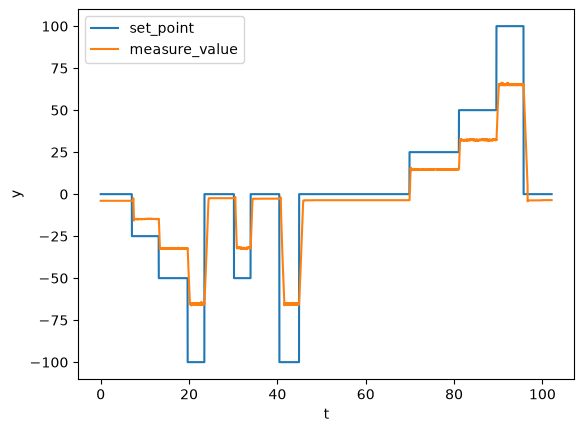

In [4]:
turn = pl.read_csv(LOG).sort("time_s")
t = turn["time_s"].to_numpy()
r = turn["set_point"].to_numpy()
y = turn["measure_value"].to_numpy()

_, ax = plt.subplots()
ax.plot(t, r, label="set_point")
ax.plot(t, y, label="measure_value")
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.legend()
turn.head()

In [ ]:
record = plantid.Log.read(LOG)
print(f"P from the config: {cfg.identify.kp:g}")

found = record.identify(cfg.identify.kp, cfg.identify.models, max_nfev=cfg.identify.max_nfev)
best = found.best
best.save(OUT)
print(best.model.name)
print(f"P = {best.kp:g}")
print(f"G(s) = {best.formula()}")
print(f"Fc = {best.plant.fc:.4g}   RMSE = {best.rmse:.4g}")
print(f"saved {OUT}")
found.table

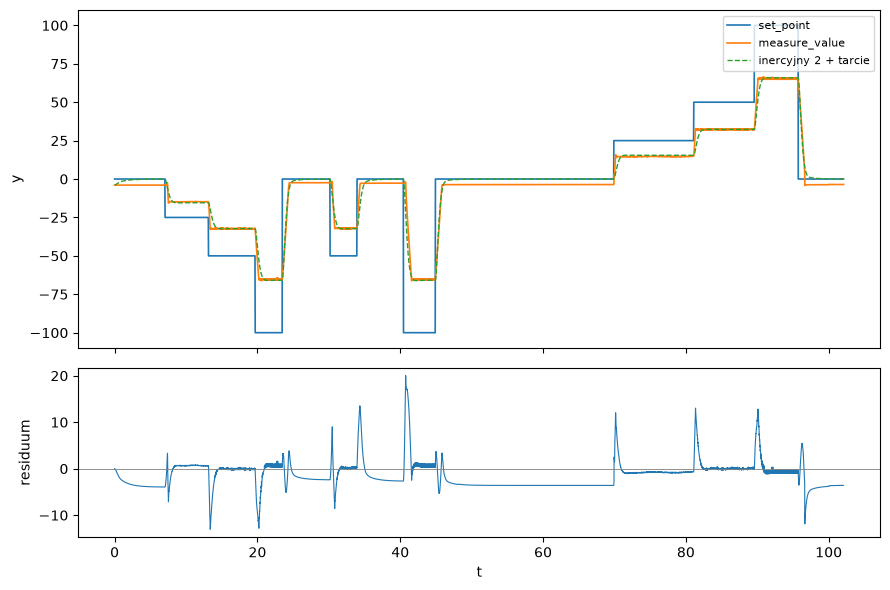

In [6]:
fig, axes = plt.subplots(
    2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": (2, 1)}
)
axes[0].plot(t, r, label="set_point", lw=1.2)
axes[0].plot(t, y, label="measure_value", lw=1.2)
axes[0].plot(t, best.prediction, ls="--", label=best.model.name, lw=1.0)
axes[0].set_ylabel("y")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(t, y - best.prediction, lw=0.8)
axes[1].axhline(0.0, color="0.5", lw=0.6)
axes[1].set_xlabel("t")
axes[1].set_ylabel("residuum")
fig.tight_layout()